=== PGP COORDINATION ===
Conflict: Agent 1 and Agent 2 at Warehouse, time 9
Resolved: Agent 2 moved to time 10
Updated plans:
Agent 1 : [('Warehouse', 9), ('Shop A', 10)]
Agent 2 : [('Warehouse', 10), ('Shop B', 11)]
Agent 3 : [('Shop C', 12)]

=== CONTRACT NET PROTOCOL ===

Task announcement: Task A
Agent 1 bids: Cost=10, Time=20
Agent 2 bids: Cost=8, Time=18
Agent 3 bids: Cost=12, Time=25
Selected agent: Agent 2
Task A assigned to Agent 2

Task announcement: Task B
Agent 1 bids: Cost=8, Time=15
Agent 2 bids: Cost=11, Time=22
Agent 3 bids: Cost=7, Time=13
Selected agent: Agent 3
Task B assigned to Agent 3

Task announcement: Task C
Agent 1 bids: Cost=12, Time=25
Agent 2 bids: Cost=7, Time=16
Agent 3 bids: Cost=9, Time=20
Selected agent: Agent 2
Task C assigned to Agent 2

Task announcement: Task D
Agent 1 bids: Cost=7, Time=12
Agent 2 bids: Cost=10, Time=20
Agent 3 bids: Cost=8, Time=17
Selected agent: Agent 1
Task D assigned to Agent 1

Task announcement: Task E
Agent 1 bids: Cost=9,

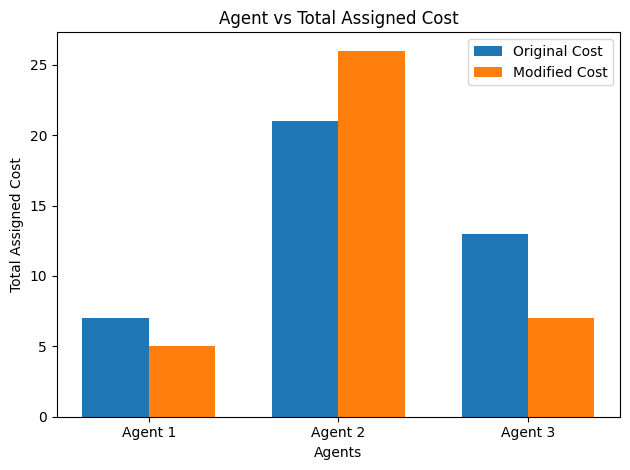

In [ ]:

import matplotlib.pyplot as plt

# ----------------------------------
# 1. Agent Setup
# ----------------------------------

agents = {
    "Agent 1": {
        "A": (10, 20), "B": (8, 15), "C": (12, 25),
        "D": (7, 12), "E": (9, 18), "F": (11, 22)
    },
    "Agent 2": {
        "A": (8, 18), "B": (11, 22), "C": (7, 16),
        "D": (10, 20), "E": (6, 14), "F": (9, 19)
    },
    "Agent 3": {
        "A": (12, 25), "B": (7, 13), "C": (9, 20),
        "D": (8, 17), "E": (10, 21), "F": (6, 12)
    }
}

tasks = ["A", "B", "C", "D", "E", "F"]

# Each cost/time pair is (cost, time).


# ----------------------------------
# 2. PGP: Conflict Detection  -> PARTIAL GLOBAL PLANNING
# ----------------------------------

print("=== PGP COORDINATION ===")

plans = {
    "Agent 1": [("Warehouse", 9), ("Shop A", 10)],
    "Agent 2": [("Warehouse", 9), ("Shop B", 11)],
    "Agent 3": [("Shop C", 12)]
}

# Detect agents using the same location at the same time.
for i, agent1 in enumerate(plans):
    for agent2 in list(plans)[i + 1:]:
        for location1, time1 in plans[agent1]:
            for location2, time2 in plans[agent2]:
                if location1 == location2 and time1 == time2:
                    print(
                        f"Conflict: {agent1} and {agent2} "
                        f"at {location1}, time {time1}"
                    )

                    # Resolve by rescheduling Agent 2.
                    plans[agent2] = [
                        (loc, time + 1 if loc == location2
                         and time == time2 else time)
                        for loc, time in plans[agent2]
                    ]

                    print(
                        f"Resolved: {agent2} moved to time {time2 + 1}"
                    )

print("Updated plans:")
for agent, plan in plans.items():
    print(agent, ":", plan)


# ----------------------------------
# 3. CNP: Task Allocation   ->CONTACT NET PROTOCOL
# ----------------------------------

def allocate_tasks(agents, tasks):
    allocation = {}
    total_cost = {agent: 0 for agent in agents}
    total_time = {agent: 0 for agent in agents}

    print("\n=== CONTRACT NET PROTOCOL ===")

    for task in tasks:
        print(f"\nTask announcement: Task {task}")

        bids = {}

        # Agents submit their cost/time bids.
        for agent, task_data in agents.items():
            cost, time = task_data[task]
            bids[agent] = (cost, time)
            print(f"{agent} bids: Cost={cost}, Time={time}")

        # Select the lowest-cost bid.
        selected = min(bids, key=lambda a: bids[a][0])
        cost, time = bids[selected]

        print(f"Selected agent: {selected}")

        allocation[task] = (selected, cost, time)
        total_cost[selected] += cost
        total_time[selected] += time

        print(f"Task {task} assigned to {selected}")

    return allocation, total_cost, total_time


# ----------------------------------
# 4. Display Final Allocation
# ----------------------------------

allocation, total_cost, total_time = allocate_tasks(
    agents, tasks
)

print("\n=== FINAL TASK ALLOCATION ===")
print(f"{'Task':<10}{'Selected Agent':<18}{'Cost':<10}{'Time':<10}")

for task, (agent, cost, time) in allocation.items():
    print(f"{task:<10}{agent:<18}{cost:<10}{time:<10}")

print("\nAgent-wise totals:")
for agent in agents:
    print(
        f"{agent}: Total Cost={total_cost[agent]}, "
        f"Total Time={total_time[agent]}"
    )

print("Overall Cost:", sum(total_cost.values()))
print("Sum of Assigned Task Times:", sum(total_time.values()))


# ----------------------------------
# 5. Modify Costs and Compare
# ----------------------------------

modified_agents = {
    agent: data.copy() for agent, data in agents.items()
}

# Modify some agent bids.
modified_agents["Agent 1"]["A"] = (5, 12)
modified_agents["Agent 2"]["D"] = (4, 10)
modified_agents["Agent 3"]["F"] = (13, 25)

new_allocation, new_cost, new_time = allocate_tasks(
    modified_agents, tasks
)

print("\n=== MODIFIED ALLOCATION ===")
for task, (agent, cost, time) in new_allocation.items():
    print(
        f"Task {task}: {agent}, Cost={cost}, Time={time}"
    )

print("\n=== COMPARISON ===")
for agent in agents:
    print(
        f"{agent}: "
        f"Old Cost={total_cost[agent]}, "
        f"New Cost={new_cost[agent]}, "
        f"Old Time={total_time[agent]}, "
        f"New Time={new_time[agent]}"
    )

# Plot agent-wise assigned cost before and after changes.
agent_names = list(agents.keys())
old_values = [total_cost[a] for a in agent_names]
new_values = [new_cost[a] for a in agent_names]

x = range(len(agent_names))
width = 0.35

plt.bar(
    [i - width / 2 for i in x],
    old_values,
    width=width,
    label="Original Cost"
)
plt.bar(
    [i + width / 2 for i in x],
    new_values,
    width=width,
    label="Modified Cost"
)

plt.xlabel("Agents")
plt.ylabel("Total Assigned Cost")
plt.title("Agent vs Total Assigned Cost")
plt.xticks(list(x), agent_names)
plt.legend()
plt.tight_layout()
plt.show()
